# Лабораторная работа №2. Классификация пассажиров Titanic

**Цель:** пройти полный цикл бинарной классификации: от первичного анализа данных и Dummy baseline до обучения пяти алгоритмов, сравнительного анализа метрик, важности признаков и ошибок.

**Датасет:** Titanic Dataset, 891 пассажир. **Целевая переменная:** `Survived` (`1` — выжил, `0` — погиб). **Основная метрика:** F1 для класса `Survived = 1`.

**Методика эксперимента:** единый стратифицированный train/test split (80/20), `random_state=42`; выбор алгоритма по пятифолдовой кросс-валидации **только на train**; тест — для итоговой оценки. Текстовые интерпретации в ноутбуке основаны на результатах выполненного запуска этой конфигурации.


## 1. Импорт библиотек и настройка среды

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
TEST_SIZE = 0.20
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)

Python: 3.13.7 | pandas: 2.3.3


## 2. Загрузка данных

Поместите скачанный файл из Kaggle рядом с ноутбуком под именем `Titanic-Dataset.csv` (или `titanic.csv` / `train.csv`). Если локального файла нет, будет предпринята загрузка открытой копии классического набора Titanic (891 строка) из репозитория DataScienceDojo. Для полного совпадения с требованиями преподавателя предпочтителен **именно файл из Kaggle**.

In [2]:
from pathlib import Path

candidates = [Path('Titanic-Dataset.csv'), Path('titanic.csv'), Path('train.csv'), Path('Titanic.csv')]
local_file = next((p for p in candidates if p.exists()), None)
if local_file is not None:
    df = pd.read_csv(local_file)
    print('Источник: локальный файл', local_file.resolve())
else:
    mirror_url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
    print('Локальный CSV не найден. Загружаем открытую копию:', mirror_url)
    try:
        df = pd.read_csv(mirror_url)
    except Exception as exc:
        raise FileNotFoundError('Не удалось загрузить CSV. Скачайте Titanic-Dataset.csv с Kaggle и поместите рядом с ноутбуком.') from exc

expected = {'Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked'}
assert expected.issubset(df.columns), f'Отсутствуют столбцы: {expected - set(df.columns)}'
assert df['Survived'].dropna().isin([0, 1]).all(), 'Survived должен содержать только 0 и 1'
print('Размер:', df.shape)
display(df.head())

Источник: локальный файл C:\Users\Ivan\Downloads\titanic.csv
Размер: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Первичный анализ данных (EDA)

Изучим структуру, типы, пропуски и полные дубликаты. Полные дубликаты и повторные идентификаторы — разные понятия: `PassengerId` не используется в обучении.

In [3]:
print('Информация о столбцах:')
df.info()
print('\nПолные дубликаты:', int(df.duplicated().sum()))
if 'PassengerId' in df:
    print('Дубликаты PassengerId:', int(df['PassengerId'].duplicated().sum()))
missing = pd.DataFrame({'Пропуски': df.isna().sum(), 'Доля, %': 100 * df.isna().mean(), 'Тип': df.dtypes.astype(str)})
display(missing.sort_values('Пропуски', ascending=False))
display(df.describe(include='all').T)

Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Полные дубликаты: 0
Дубликаты PassengerId: 0


,Пропуски,"Доля, %",Тип
Cabin,687,77.104377,object
Age,177,19.865320,float64
Embarked,2,0.224467,object
PassengerId,0,0.000000,int64
Name,0,0.000000,object
Pclass,0,0.000000,int64
Survived,0,0.000000,int64
Sex,0,0.000000,object
Parch,0,0.000000,int64
SibSp,0,0.000000,int64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


### 3.1. Распределение целевой переменной

,Количество,"Доля, %"
Survived,,
0,549,61.62
1,342,38.38


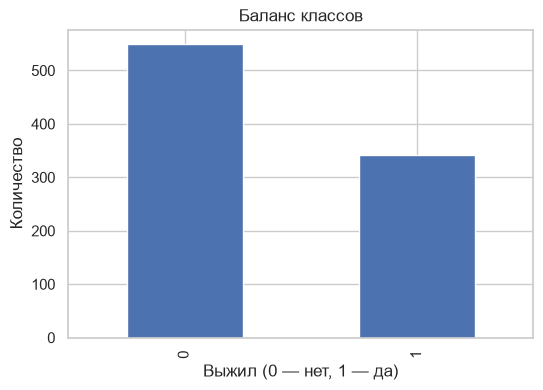

In [4]:
distribution = df['Survived'].value_counts().sort_index()
display(pd.DataFrame({'Количество': distribution, 'Доля, %': (distribution / len(df) * 100).round(2)}))
fig, ax = plt.subplots(figsize=(6,4))
distribution.reindex([0,1], fill_value=0).plot.bar(ax=ax)
ax.set(xlabel='Выжил (0 — нет, 1 — да)', ylabel='Количество', title='Баланс классов')
plt.show()

### 3.2. Зависимость выживания от доступных признаков

Ниже приведены **описательные**, а не причинно-следственные связи.

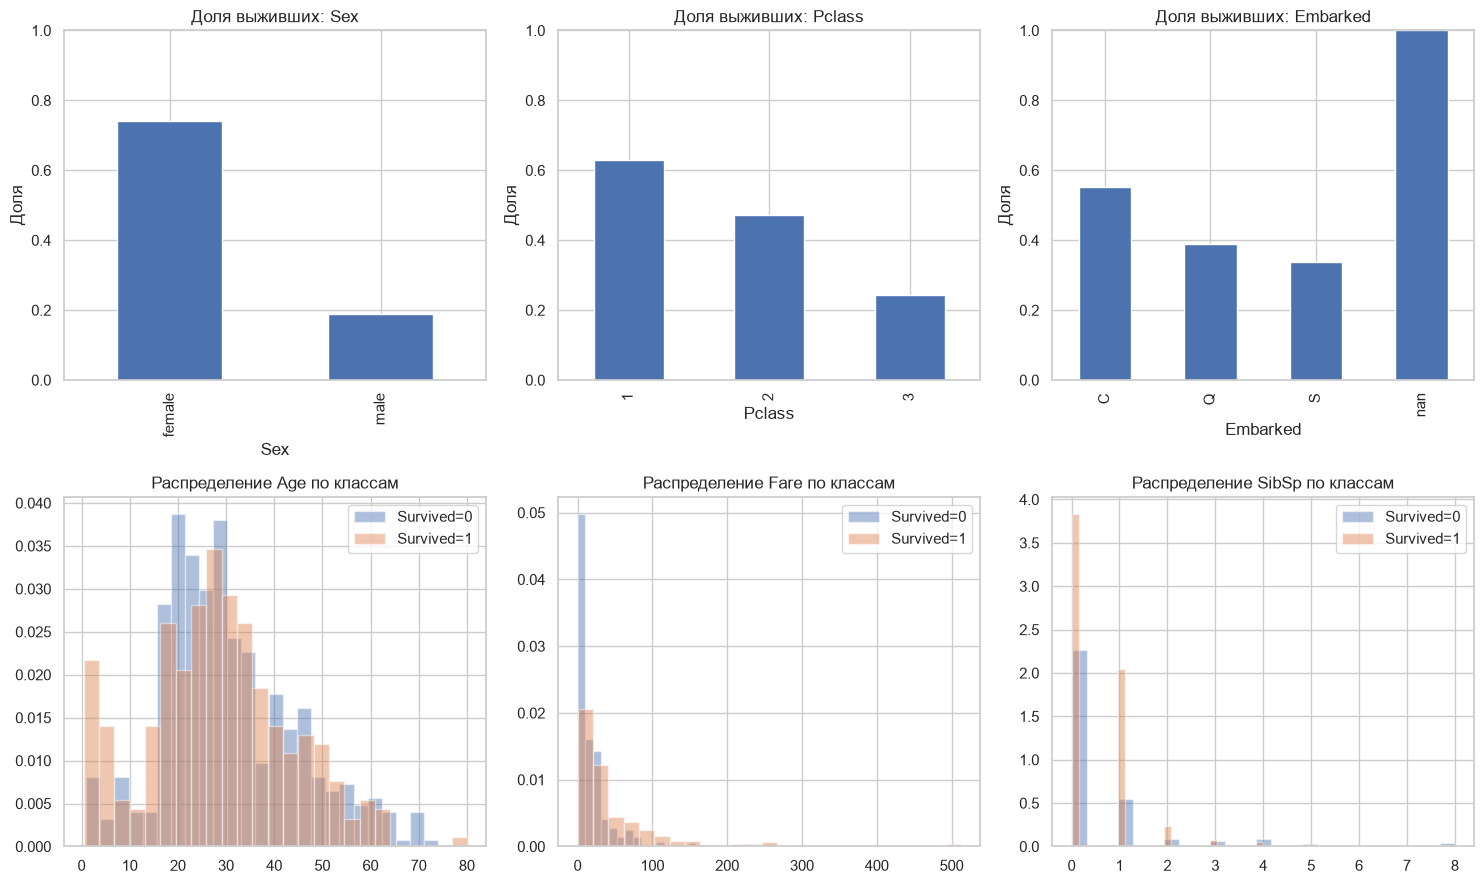

Выживаемость по Sex:


,Количество,Доля выживших
Sex,,
female,314,0.742
male,577,0.189


Выживаемость по Pclass:


,Количество,Доля выживших
Pclass,,
1,216,0.630
2,184,0.473
3,491,0.242


Выживаемость по Embarked:


,Количество,Доля выживших
Embarked,,
C,168,0.554
Q,77,0.390
S,644,0.337
NaN,2,1.000


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.flat[:3], ['Sex', 'Pclass', 'Embarked']):
    rates = df.groupby(col, dropna=False)['Survived'].agg(['mean','count'])
    rates['mean'].plot.bar(ax=ax, ylim=(0, 1))
    ax.set_title(f'Доля выживших: {col}')
    ax.set_ylabel('Доля')
for ax, col in zip(axes.flat[3:], ['Age','Fare','SibSp']):
    [ax.hist(df.loc[df['Survived']==class_label, col].dropna(), bins=25, density=True, alpha=0.45, label=f'Survived={class_label}') for class_label in [0,1]]
    ax.legend()
    ax.set_title(f'Распределение {col} по классам')
plt.tight_layout()
plt.show()
for col in ['Sex','Pclass','Embarked']:
    print(f'Выживаемость по {col}:')
    display((df.groupby(col, dropna=False)['Survived'].agg(['size','mean']).rename(columns={'size':'Количество','mean':'Доля выживших'})).round(3))

### Выводы по первичному анализу

Исходный набор содержит **891 строку и 12 столбцов**. Полных дубликатов нет; повторяющихся значений `PassengerId` также нет. Переменная `Survived` бинарная: погибло **549 пассажиров (61,62%)**, выжило **342 (38,38%)**. Классы несбалансированы умеренно, поэтому одной Accuracy недостаточно, а основной метрикой выбран F1 положительного класса.

Пропуски обнаружены в `Cabin` — **687 (77,10%)**, `Age` — **177 (19,87%)**, `Embarked` — **2 (0,22%)**. В остальных столбцах пропусков нет. `Pclass` хранится числом, однако обозначает категорию класса билета; `Sex` и `Embarked` являются категориальными, а `Age`, `Fare`, `SibSp`, `Parch` — числовыми. Признак `Cabin` имеет слишком много пропусков для надёжного использования в исходном виде.

При описательном анализе доля выживших составила **74,2% среди женщин против 18,9% среди мужчин**. Для 1-го, 2-го и 3-го классов доли составили **63,0%, 47,3% и 24,2%** соответственно. Для портов `C`, `Q`, `S` доли выживших были **55,4%, 39,0% и 33,7%**; группу с пропущенным портом (2 объекта) интерпретировать нельзя из-за малого размера. Эти зависимости показывают, что `Sex` и `Pclass` перспективны для прогнозирования, но **не доказывают причинно-следственную связь**.

`PassengerId`, `Name`, `Ticket` и `Cabin` исключены из признаков модели: первые три могут прямо или косвенно идентифицировать пассажира/группу, а исходный `Cabin` дополнительно обладает высокой разреженностью и может кодировать конкретное размещение. Данные `Survived` используются только как целевая переменная, а не как входной признак.


## 4. Подготовка данных и разбиение

Используем исходные признаки `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked` и два простых производных признака: `FamilySize = SibSp + Parch + 1` и `IsAlone`. Эти признаки вычисляются из данных **одного объекта** и не используют целевую переменную.

`Age`, `Fare` и числовые семейные признаки заполняем медианой; `Sex`, `Embarked`, `Pclass` — наиболее частой категорией. Категории кодируются One-Hot. Для SVM и KNN числовые признаки стандартизируются: иначе большие значения `Fare` доминируют в расстояниях и RBF-ядре. Деревьям масштабирование не требуется.

**Важно:** сначала выделяем train/test, а затем внутри каждого `Pipeline` оцениваем медианы, моды, статистики стандартизации и категории строго по train (и по соответствующей обучающей части каждого CV-fold).

In [6]:
data = df.copy()
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1
data['IsAlone'] = (data['FamilySize'] == 1).astype(int).astype(str)

num_cols = ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize']
cat_cols = ['Pclass', 'Sex', 'Embarked', 'IsAlone']
X = data[num_cols + cat_cols].copy()
X['Pclass'] = X['Pclass'].astype('object')
y = data['Survived'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Доли Survived=1: train =', round(y_train.mean(), 4), ', test =', round(y_test.mean(), 4))
assert set(X_train.index).isdisjoint(set(X_test.index))

def make_ohe():
    # совместимость разных версий scikit-learn
    try:
        return OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown='ignore', sparse=False)

def make_preprocessor(scale=False):
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(num_steps), num_cols),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', make_ohe())]), cat_cols)
    ])

Train: (712, 9) Test: (179, 9)
Доли Survived=1: train = 0.3834 , test = 0.3855


## 5. Метрики, baseline и процедура честного сравнения

- **Accuracy** — доля всех верных ответов.
- **Precision** — доля действительно выживших среди предсказанных выжившими: `TP / (TP + FP)`.
- **Recall** — доля обнаруженных выживших среди всех выживших: `TP / (TP + FN)`.
- **F1** — гармоническое среднее Precision и Recall, основная метрика для `Survived=1`.

**False Positive (FP):** модель предсказала спасение, но пассажир погиб. **False Negative (FN):** модель предсказала гибель, но пассажир выжил. Матрица ошибок будет построена для всех шести решений.

Для подбора решения сравним средний F1 на пяти стратифицированных фолдах train. Гиперпараметры заданы заранее; тест на выбор параметров не влияет.

In [7]:
models = {
    'Dummy baseline': DummyClassifier(strategy='most_frequent'),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, min_samples_leaf=8, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=250, max_depth=7, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=160, learning_rate=0.05, max_depth=3, min_samples_leaf=5, random_state=RANDOM_STATE),
    'SVM (RBF)': SVC(C=1.5, kernel='rbf', gamma='scale'),
    'KNN': KNeighborsClassifier(n_neighbors=9, weights='distance')
}

pipelines = {
    name: Pipeline([('preprocess', make_preprocessor(scale=name in ['SVM (RBF)', 'KNN'])), ('classifier', clf)])
    for name, clf in models.items()
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring={'f1':'f1', 'accuracy':'accuracy'}, n_jobs=1)
    cv_rows.append({'Модель':name, 'F1 CV mean':scores['test_f1'].mean(), 'F1 CV std':scores['test_f1'].std(), 'Accuracy CV mean':scores['test_accuracy'].mean()})
cv_df = pd.DataFrame(cv_rows).sort_values('F1 CV mean', ascending=False).reset_index(drop=True)
display(cv_df.round(4))
best_name = cv_df.loc[0,'Модель']
print('Лучшая модель по кросс-валидации на train:', best_name)

,Модель,F1 CV mean,F1 CV std,Accuracy CV mean
0,Gradient Boosting,0.7534,0.0364,0.8202
1,SVM (RBF),0.7479,0.0280,0.8216
2,Random Forest,0.7374,0.0354,0.8160
3,KNN,0.7162,0.0131,0.7865
4,Decision Tree,0.7112,0.0209,0.7908
5,Dummy baseline,0.0000,0.0000,0.6166


Лучшая модель по кросс-валидации на train: Gradient Boosting


## 6. Финальное обучение и единая оценка на test

После выбора лучшей модели по CV обучаем все шесть пайплайнов на **одном и том же train**. Один раз вычисляем результаты на **одном и том же test** — только для финального сравнения и анализа ошибок, без повторного подбора гиперпараметров.

In [8]:
fitted = {}
predictions = {}
rows = []
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred_train = pipe.predict(X_train)
    pred_test = pipe.predict(X_test)
    predictions[name] = pred_test
    rows.append({
        'Модель':name,
        'Accuracy':accuracy_score(y_test, pred_test),
        'Precision':precision_score(y_test, pred_test, zero_division=0),
        'Recall':recall_score(y_test, pred_test, zero_division=0),
        'F1':f1_score(y_test, pred_test, zero_division=0),
        'F1 train':f1_score(y_train, pred_train, zero_division=0),
        'F1 CV':cv_df.set_index('Модель').loc[name, 'F1 CV mean'],
    })
results_df = pd.DataFrame(rows).sort_values('F1', ascending=False).reset_index(drop=True)
display(results_df.round(4))
print('Порог F1 > 0.70 преодолели:', results_df.loc[results_df['F1'] > .70, 'Модель'].tolist())
print('Лучшая модель была выбрана заранее по CV:', best_name)
print('Её тестовый F1:', round(float(results_df.set_index('Модель').loc[best_name, 'F1']),4))

,Модель,Accuracy,Precision,Recall,F1,F1 train,F1 CV
0,KNN,0.7933,0.7424,0.7101,0.7259,0.9776,0.7162
1,Random Forest,0.8156,0.8600,0.6232,0.7227,0.8209,0.7374
2,SVM (RBF),0.8045,0.8036,0.6522,0.7200,0.7802,0.7479
3,Gradient Boosting,0.7933,0.7857,0.6377,0.7040,0.8427,0.7534
4,Decision Tree,0.7542,0.7193,0.5942,0.6508,0.7859,0.7112
5,Dummy baseline,0.6145,0.0000,0.0000,0.0000,0.0000,0.0000


Порог F1 > 0.70 преодолели: ['KNN', 'Random Forest', 'SVM (RBF)', 'Gradient Boosting']
Лучшая модель была выбрана заранее по CV: Gradient Boosting
Её тестовый F1: 0.704


### 6.1. Confusion matrix для baseline и всех моделей

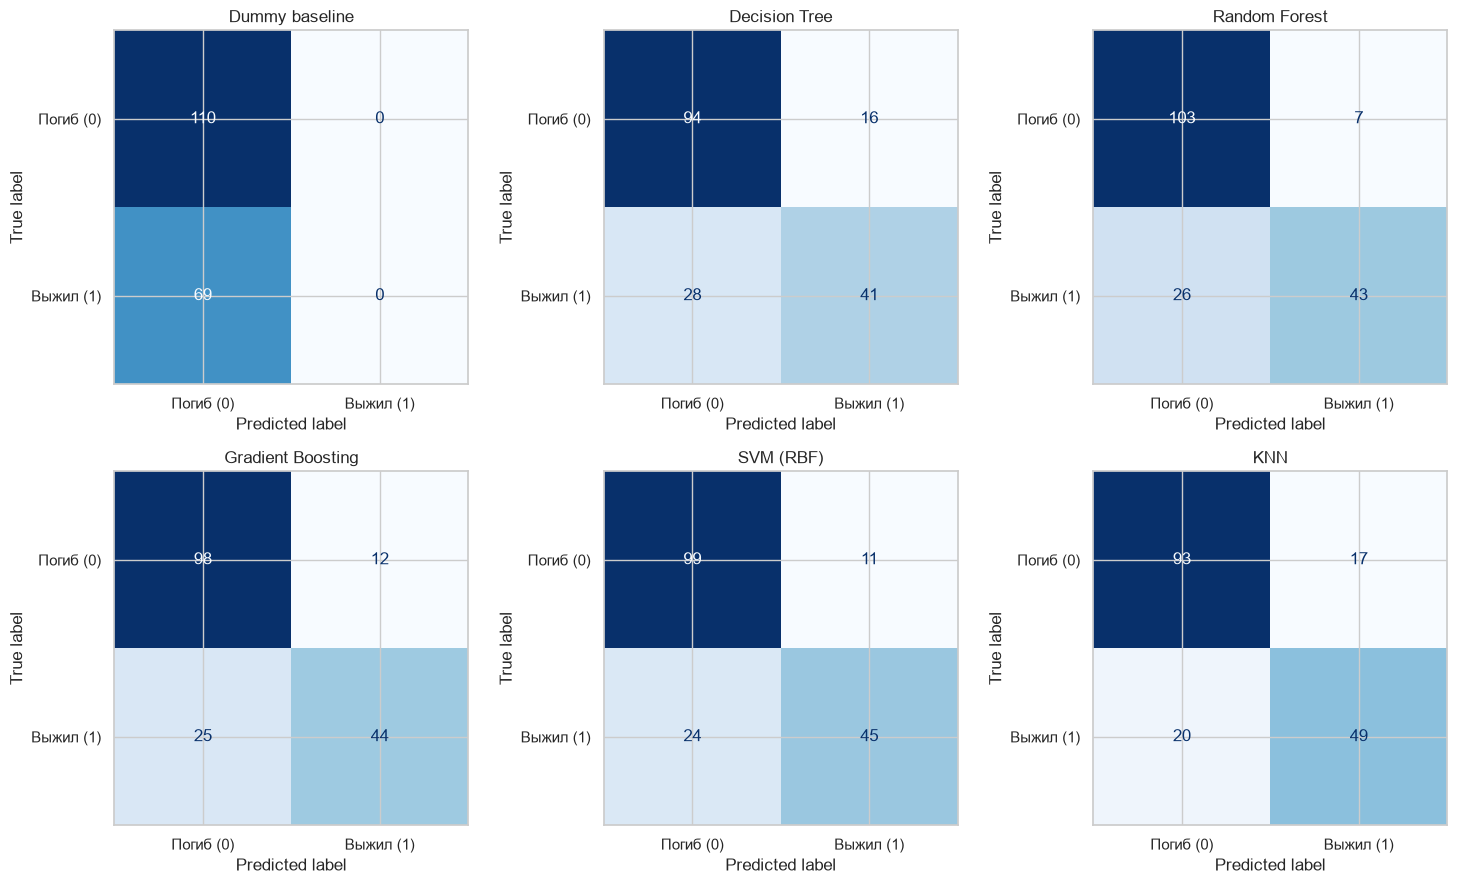

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, prediction) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, prediction, labels=[0,1]), display_labels=['Погиб (0)','Выжил (1)']).plot(ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 6.2. Визуальное сравнение метрик и переобучения

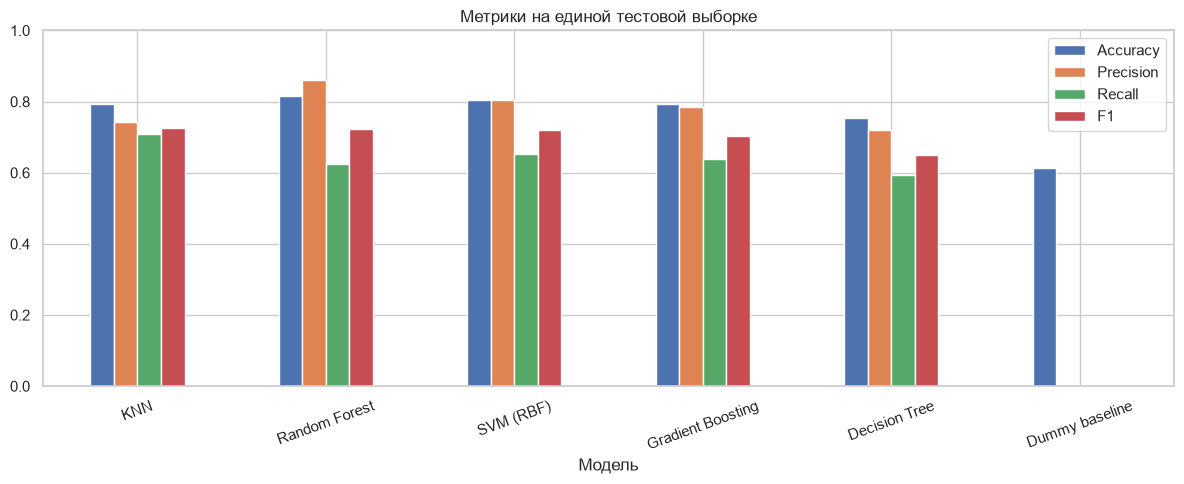

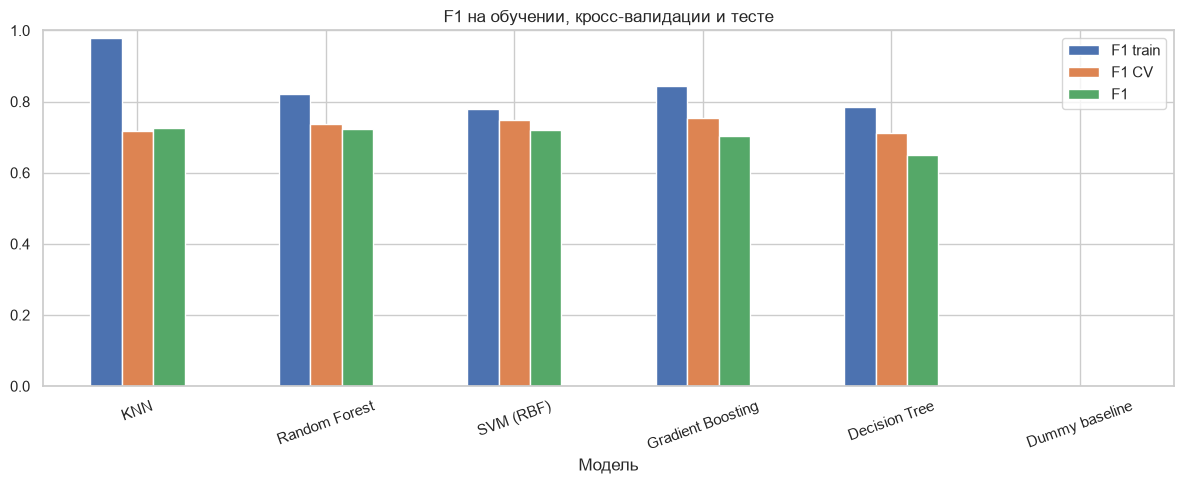

Разница F1(train) – F1(test) для дерева: 0.1351


In [10]:
results_df.set_index('Модель')[['Accuracy','Precision','Recall','F1']].plot.bar(figsize=(12,5), ylim=(0,1), rot=20)
plt.title('Метрики на единой тестовой выборке')
plt.tight_layout()
plt.show()
results_df.set_index('Модель')[['F1 train','F1 CV','F1']].plot.bar(figsize=(12,5), ylim=(0,1), rot=20)
plt.title('F1 на обучении, кросс-валидации и тесте')
plt.tight_layout()
plt.show()
print('Разница F1(train) – F1(test) для дерева:', round(float(results_df.set_index('Модель').loc['Decision Tree','F1 train'] - results_df.set_index('Модель').loc['Decision Tree','F1']),4))

### Промежуточные выводы по моделям

Всем моделям предоставлены одни и те же **712 объектов train и 179 объектов test**, где доля выживших равна 38,34% и 38,55% соответственно. Для Dummy baseline наиболее частый класс на обучении — `0` (погиб), поэтому его предсказания всегда отрицательные. На тесте он получает **Accuracy = 0,6145**, но **Precision = Recall = F1 = 0** для класса выживших. Это показывает, почему Accuracy не следует использовать как единственный критерий.

По **пятифолдовой CV на train** лидирует **Gradient Boosting (F1 = 0,7534 ± 0,0364)**; следующие — SVM (0,7479), Random Forest (0,7374), KNN (0,7162), Decision Tree (0,7112). Gradient Boosting **выбран до анализа тестовых метрик**. Его тестовый F1 составил **0,7040**, т. е. порог лабораторной **строго F1 > 0,70** пройден.

На тестовой выборке F1 распределился так: **KNN — 0,7259**, **Random Forest — 0,7227**, **SVM — 0,7200**, **Gradient Boosting — 0,7040**, **Decision Tree — 0,6508**. Порог превысили **четыре** модели из пяти (не считая baseline). Хотя тестовое значение KNN выше, переобъявлять его «выбранной лучшей моделью» по результатам test некорректно: это было бы использованием отложенной выборки для выбора алгоритма.

Различия обусловлены индуктивными предположениями алгоритмов, сложностью зависимостей, параметрами регуляризации и объёмом доступных данных. Для Random Forest характерна **высокая Precision = 0,8600** при более низкой **Recall = 0,6232**: модель редко ошибочно предсказывает выживание, но пропускает значительную часть действительно выживших. KNN имеет более высокую **Recall = 0,7101**, при этом его Precision = 0,7424. Gradient Boosting показал Precision = 0,7857 и Recall = 0,6377: пропуск выживших является более заметной проблемой.

**Переобучение:** у Decision Tree F1 составляет **0,7859 на train**, **0,7112 на CV** и **0,6508 на test**; разница train–test равна **0,1351**, что указывает на признаки переобучения или нестабильность оценки на сравнительно небольшом тесте. Особенно выражен разрыв у KNN: **0,9776 на train** против **0,7162 на CV** и **0,7259 на test**. При `weights='distance'` модель может почти идеально предсказывать обучающие объекты за счёт нулевого расстояния до самих себя, но это не переносится на новые данные. У Random Forest (train F1 = 0,8209) и Gradient Boosting (0,8427) также наблюдается разрыв с CV/test, однако он существенно меньше, чем у KNN.


## 7. Feature Importance: Decision Tree, Random Forest, Gradient Boosting

Для каждой модели выводим важность закодированных признаков, затем агрегируем One-Hot столбцы по исходному признаку. Важность дерева по уменьшению impurity отражает **использование признака моделью**, не причинное влияние. Коррелирующие признаки могут разделять важность между собой.


 Decision Tree — топ-10 закодированных признаков


,Важность
cat__Sex_male,0.5777
cat__Pclass_3,0.1440
num__Age,0.0931
num__Fare,0.0644
cat__Pclass_1,0.0523
num__FamilySize,0.0476
cat__Embarked_S,0.0190
num__SibSp,0.0018
num__Parch,0.0000
cat__Pclass_2,0.0000



 Random Forest — топ-10 закодированных признаков


,Важность
cat__Sex_female,0.2317
cat__Sex_male,0.2126
num__Fare,0.1533
num__Age,0.1122
cat__Pclass_3,0.0690
cat__Pclass_1,0.0500
num__FamilySize,0.0454
num__SibSp,0.0226
cat__Pclass_2,0.0193
num__Parch,0.0192



 Gradient Boosting — топ-10 закодированных признаков


,Важность
cat__Sex_male,0.3379
cat__Sex_female,0.1544
num__Fare,0.1372
num__Age,0.1316
cat__Pclass_3,0.1248
num__FamilySize,0.0395
cat__Pclass_1,0.0376
cat__Embarked_S,0.0212
num__SibSp,0.0133
cat__Embarked_C,0.0011


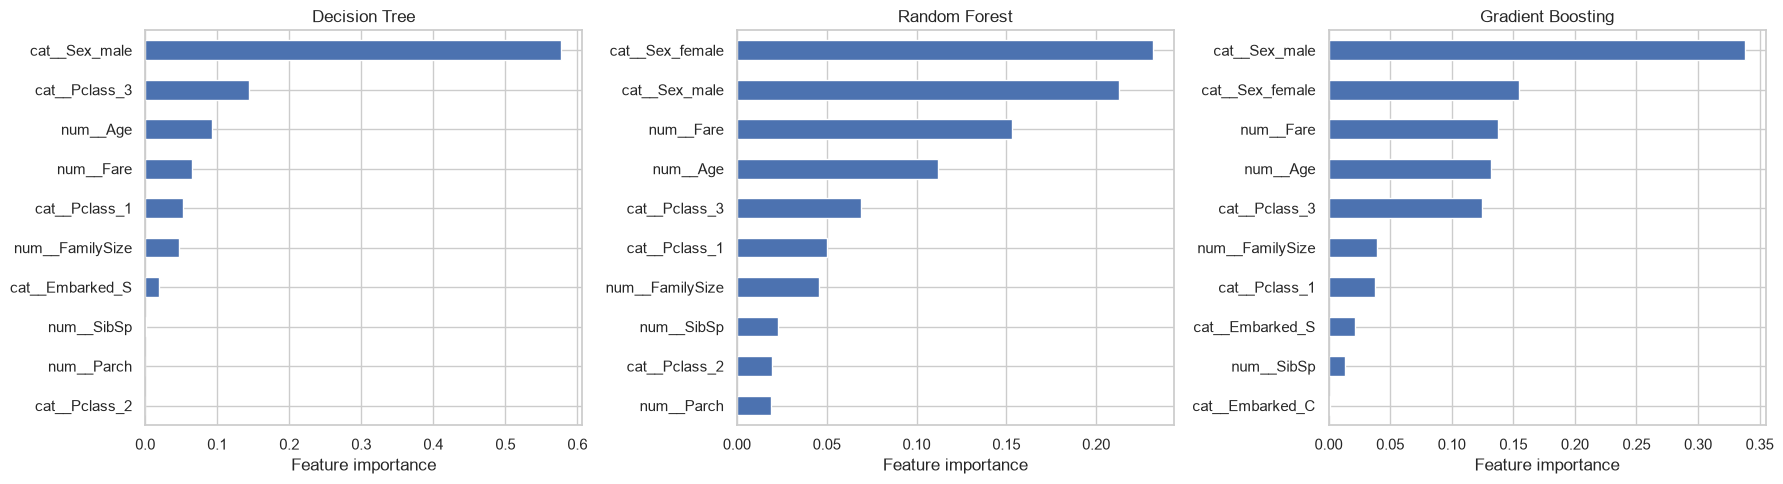

In [11]:
importance_by_model = {}
all_orig = num_cols + cat_cols
for model_name in ['Decision Tree','Random Forest','Gradient Boosting']:
    pipe = fitted[model_name]
    prep = pipe.named_steps['preprocess']
    names = prep.get_feature_names_out()
    importances = pipe.named_steps['classifier'].feature_importances_
    detailed = pd.Series(importances, index=names).sort_values(ascending=False)
    importance_by_model[model_name] = detailed
    print('\n', model_name, '— топ-10 закодированных признаков')
    display(detailed.head(10).to_frame('Важность').round(4))

fig, axes = plt.subplots(1, 3, figsize=(18,5))
for ax, (name, imp) in zip(axes, importance_by_model.items()):
    imp.head(10).sort_values().plot.barh(ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Feature importance')
plt.tight_layout()
plt.show()

Суммарная важность по исходным признакам:


,Decision Tree,Random Forest,Gradient Boosting
Sex,0.5777,0.4442,0.4923
Fare,0.0644,0.1533,0.1372
Pclass,0.1964,0.1383,0.1627
Age,0.0931,0.1122,0.1316
FamilySize,0.0476,0.0454,0.0395
Embarked,0.0190,0.0403,0.0224
IsAlone,0.0000,0.0243,0.0003
SibSp,0.0018,0.0226,0.0133
Parch,0.0000,0.0192,0.0007


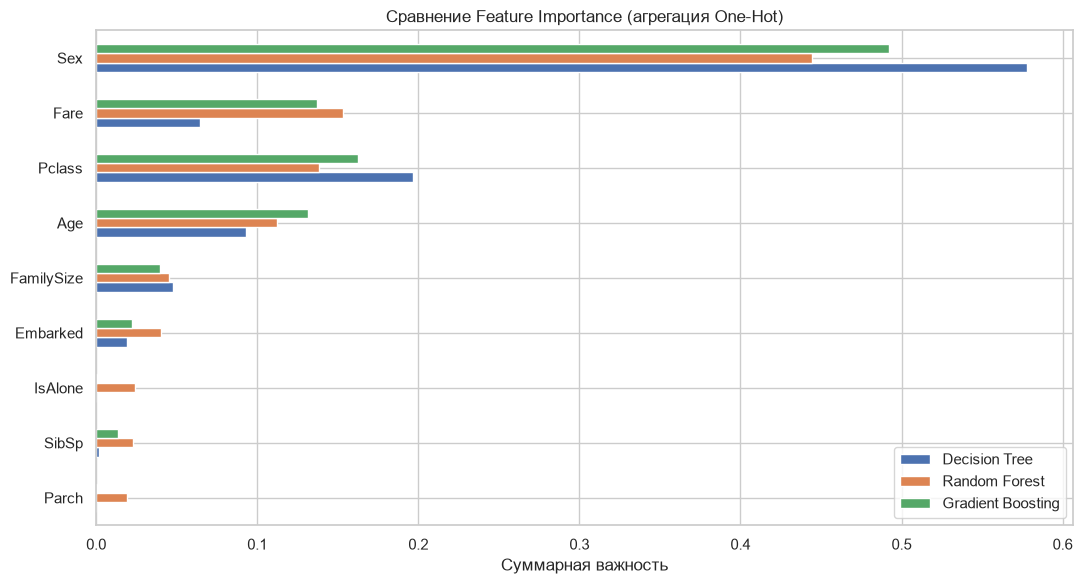

In [12]:
# Агрегация весов one-hot признаков по исходным группам.
# Категориальные названия формируются как cat__Sex_male, cat__Embarked_S и т.п.
def original_feature(encoded_name):
    if encoded_name.startswith('num__'):
        return encoded_name[len('num__'):]
    suffix = encoded_name[len('cat__'):]
    for feature in sorted(cat_cols, key=len, reverse=True):
        if suffix == feature or suffix.startswith(feature + '_'):
            return feature
    raise ValueError('Неизвестный признак: ' + encoded_name)

aggregated = pd.DataFrame({
    name: importance.groupby(importance.index.map(original_feature)).sum()
    for name, importance in importance_by_model.items()
}).fillna(0).reindex(all_orig)
print('Суммарная важность по исходным признакам:')
display(aggregated.round(4).sort_values('Random Forest', ascending=False))
aggregated.sort_values('Random Forest').plot.barh(figsize=(11,6))
plt.title('Сравнение Feature Importance (агрегация One-Hot)')
plt.xlabel('Суммарная важность')
plt.tight_layout()
plt.show()

### Интерпретация Feature Importance

Важности закодированных категорий `OneHotEncoder` суммированы по исходным признакам. Во всех трёх моделях **наиболее значим `Sex`**: Decision Tree — **0,5777**, Random Forest — **0,4442**, Gradient Boosting — **0,4923**. Это согласуется с EDA: доля выживших среди женщин (74,2%) существенно выше, чем среди мужчин (18,9%).

Далее модели несколько расходятся по порядку. Для **Decision Tree** лидируют `Sex` (0,5777), `Pclass` (0,1964) и `Age` (0,0931). Для **Random Forest** — `Sex` (0,4442), `Fare` (0,1533), `Pclass` (0,1383) и `Age` (0,1122). Для **Gradient Boosting** — `Sex` (0,4923), `Pclass` (0,1627), `Fare` (0,1372), `Age` (0,1316). Значимость `Pclass` также согласуется с найденными различиями выживаемости между классами.

`Fare` и `Pclass` могут отражать частично общую информацию о категории поездки и социально-экономическом положении; наличие `FamilySize` вместе с `SibSp` и `Parch` также создаёт взаимосвязанные признаки. Поэтому распределение важностей между коррелирующими столбцами следует интерпретировать осторожно. Кроме того, встроенная impurity-based importance может быть смещена в пользу некоторых непрерывных/высококардинальных признаков.

**Нельзя заключать, что важный признак является причиной выживания.** Важность показывает вклад в разбиения и предсказания *конкретной обученной модели*, а не результат контролируемого эксперимента. На наблюдаемые связи могли влиять правила эвакуации, доступность шлюпок, расположение кают и другие факторы, часть которых отсутствует в датасете.


## 8. Подробный анализ ошибок выбранной по CV модели

Для избежания подбора по тесту используем `best_name` — модель, выбранную исключительно на обучающей части. Анализируем распределение FP/FN, частоты ошибок в группах и конкретные случаи. В разборе показываем исходные столбцы только **для описания**, не подаём идентификаторы в классификатор.

In [13]:
best_pred = predictions[best_name]
cm = confusion_matrix(y_test, best_pred, labels=[0,1])
tn, fp, fn, tp = cm.ravel()
print('Выбранная модель:',best_name, '| TN:',tn,'FP:',fp,'FN:',fn,'TP:',tp)
print('Чаще:', 'FP' if fp>fn else 'FN' if fn>fp else 'одинаково FP и FN')

analysis = df.loc[X_test.index, [col for col in ['PassengerId','Name','Sex','Pclass','Age','Fare','Embarked','SibSp','Parch'] if col in df.columns]].copy()
analysis['True'] = y_test
analysis['Predicted'] = best_pred
analysis['Error'] = analysis['True'].ne(analysis['Predicted'])
analysis['ErrorType'] = np.select(
    [analysis['True'].eq(0) & analysis['Predicted'].eq(1), analysis['True'].eq(1) & analysis['Predicted'].eq(0)],
    ['FP', 'FN'], default='Correct')

for group in ['Sex','Pclass','Embarked']:
    print('\nОшибка по группе:', group)
    tab = analysis.groupby(group, dropna=False).agg(Количество=('Error','size'), Ошибок=('Error','sum'), Доля_ошибок=('Error','mean'))
    display(tab.sort_values('Доля_ошибок', ascending=False).round(3))

analysis['AgeGroup'] = pd.cut(analysis['Age'], bins=[0,12,18,35,60,np.inf], labels=['0–12','13–18','19–35','36–60','60+'], include_lowest=True)
print('\nОшибка по возрастным группам:')
display(analysis.groupby('AgeGroup', observed=False).agg(Количество=('Error','size'), Ошибок=('Error','sum'), Доля_ошибок=('Error','mean')).round(3))

Выбранная модель: Gradient Boosting | TN: 98 FP: 12 FN: 25 TP: 44
Чаще: FN

Ошибка по группе: Sex


,Количество,Ошибок,Доля_ошибок
Sex,,,
male,118,25,0.212
female,61,12,0.197



Ошибка по группе: Pclass


,Количество,Ошибок,Доля_ошибок
Pclass,,,
1,45,13,0.289
3,100,20,0.200
2,34,4,0.118



Ошибка по группе: Embarked


,Количество,Ошибок,Доля_ошибок
Embarked,,,
C,29,8,0.276
S,128,25,0.195
Q,22,4,0.182



Ошибка по возрастным группам:


,Количество,Ошибок,Доля_ошибок
AgeGroup,,,
0–12,14,5,0.357
13–18,17,0,0.000
19–35,74,14,0.189
36–60,28,7,0.250
60+,6,1,0.167


Всего ошибок: 37
Несколько примеров FP и FN (без использования идентификаторов при обучении):

Тип: FP


,PassengerId,Name,Sex,Pclass,Age,Fare,Embarked,SibSp,Parch,True,Predicted,Error,ErrorType,AgeGroup
536,537,"Butt, Major. Archibald Willingham",male,1,45.0,26.5500,S,0,0,0,1,True,FP,36–60
698,699,"Thayer, Mr. John Borland",male,1,49.0,110.8833,C,1,1,0,1,True,FP,36–60
297,298,"Allison, Miss. Helen Loraine",female,1,2.0,151.5500,S,1,2,0,1,True,FP,0–12
502,503,"O'Sullivan, Miss. Bridget Mary",female,3,NaN,7.6292,Q,0,0,0,1,True,FP,NaN
578,579,"Caram, Mrs. Joseph (Maria Elias)",female,3,NaN,14.4583,C,1,0,0,1,True,FP,NaN



Тип: FN


,PassengerId,Name,Sex,Pclass,Age,Fare,Embarked,SibSp,Parch,True,Predicted,Error,ErrorType,AgeGroup
553,554,"Leeni, Mr. Fahim (""Philip Zenni"")",male,3,22.0,7.225,C,0,0,1,0,True,FN,19–35
559,560,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",female,3,36.0,17.400,S,1,0,1,0,True,FN,36–60
216,217,"Honkanen, Miss. Eliina",female,3,27.0,7.925,S,0,0,1,0,True,FN,19–35
279,280,"Abbott, Mrs. Stanton (Rosa Hunt)",female,3,35.0,20.250,S,1,1,1,0,True,FN,19–35
712,713,"Taylor, Mr. Elmer Zebley",male,1,48.0,52.000,S,1,0,1,0,True,FN,36–60


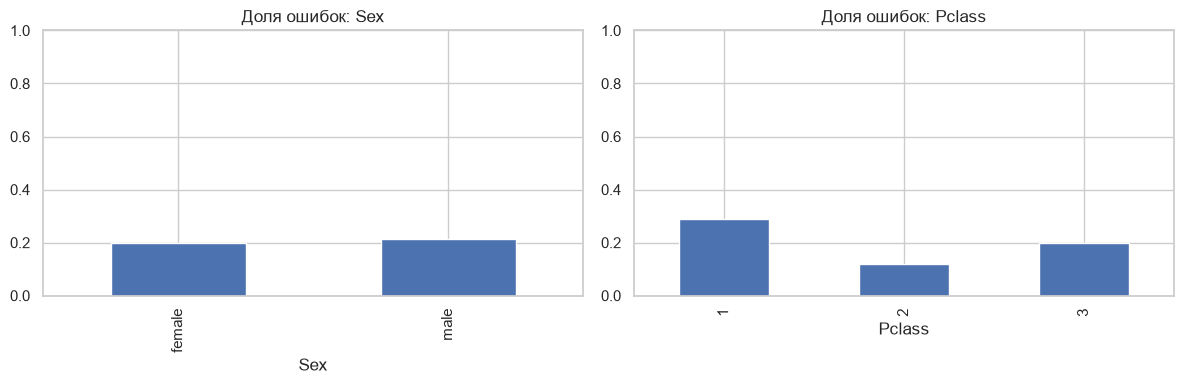

In [14]:
errors = analysis[analysis['Error']].copy()
print('Всего ошибок:',len(errors))
print('Несколько примеров FP и FN (без использования идентификаторов при обучении):')
for error_type in ['FP','FN']:
    print('\nТип:',error_type)
    display(errors.loc[errors['ErrorType']==error_type].head(5))

fig, axes = plt.subplots(1, 2, figsize=(12,4))
for ax, col in zip(axes, ['Sex','Pclass']):
    analysis.groupby(col)['Error'].mean().plot.bar(ax=ax)
    ax.set_ylim(0,1)
    ax.set_title('Доля ошибок: '+col)
plt.tight_layout()
plt.show()

### Интерпретация ошибок выбранной модели

Для предварительно выбранного **Gradient Boosting** confusion matrix (порядок классов `0`, `1`) даёт **TN = 98, FP = 12, FN = 25, TP = 44**. Всего допущено **37 ошибок из 179 наблюдений (20,7%)**. Более распространённый тип ошибки — **FN**: модель предсказала гибель 25 пассажиров, которые в действительности выжили. Для сравнения, **FP = 12** означает, что модель ошибочно предсказала выживание погибших пассажиров. В контексте задачи высокая доля FN уменьшает полноту обнаружения выживших.

По наблюдаемой доле неверных прогнозов группы распределились следующим образом:

- **Пол:** мужчины — 25/118 (**21,2%**), женщины — 12/61 (**19,7%**). Разница небольшая.
- **Класс:** 1-й — 13/45 (**28,9%**), 3-й — 20/100 (**20,0%**), 2-й — 4/34 (**11,8%**). Наибольшая доля ошибок наблюдается у 1-го класса, хотя абсолютное число ошибок больше у 3-го.
- **Порт посадки:** `C` — 8/29 (**27,6%**), `S` — 25/128 (**19,5%**), `Q` — 4/22 (**18,2%**).
- **Возраст среди пассажиров с указанным возрастом:** 0–12 лет — 5/14 (**35,7%**), 13–18 — 0/17 (0%), 19–35 — 14/74 (**18,9%**), 36–60 — 7/28 (**25,0%**), старше 60 — 1/6 (**16,7%**). Пассажиры с пропущенным `Age` не входят в эти возрастные группы: проценты не описывают их ошибки.

Отдельные случаи из выведенной таблицы помогают понять границы статистических закономерностей. Например, **FP** для пассажира `PassengerId=298` (женщина, 2 года, 1-й класс) показывает, что сочетание обычно благоприятных по EDA признаков не гарантирует спасения. **FP** для `PassengerId=699` (мужчина, 1-й класс, дорогой билет) демонстрирует аналогичное ограничение. **FN** для `PassengerId=554` (мужчина, 22 года, 3-й класс) иллюстрирует противоположную ситуацию: выживший пассажир с характеристиками, часто ассоциированными с низкой выживаемостью, был ошибочно отнесён к классу `0`. Это **гипотезы об источниках ошибки**, а не доказательства причин индивидуальных исходов.

Размеры подгрупп невелики (например, 6 человек старше 60 лет), поэтому наблюдаемые проценты могут значительно колебаться при другом разбиении. Улучшать модель по этим тестовым ошибкам в рамках данного эксперимента нельзя: для проверки новых решений понадобится независимая валидация внутри train или новый отложенный тест.


### Проверка отсутствия идентифицирующих признаков и утечек

В модель подаются только `Age`, `SibSp`, `Parch`, `Fare`, `FamilySize`, `Pclass`, `Sex`, `Embarked`, `IsAlone`. **Не используются при обучении** `PassengerId`, `Name`, `Ticket`, `Cabin` и `Survived`. Идентификатор и имя выводятся **только после предсказания** для разбора индивидуальных ошибок и не передаются в `X`.

Пропуски заполняются, категории кодируются, а признаки масштабируются посредством `Pipeline` / `ColumnTransformer`, подгоняемых только на обучающих данных. При CV эти операции дополнительно переобучаются внутри каждого обучающего фолда. `FamilySize` и `IsAlone` вычисляются лишь из признаков самого пассажира без обращения к целевой метке. **Таким образом, явная утечка меток и запоминание по идентификаторам в данной схеме предотвращены.**

Ограничение: семьи и совместно путешествовавшие пассажиры в Titanic могут оказаться в обеих частях случайного разбиения. Исключение `Ticket` снижает риск идентификации, но полностью не доказывает статистической независимости пассажиров. Сравнение на общей тестовой выборке группы также нельзя проверить без конкретного файла/индексов разбиения, предоставленных преподавателем.


In [15]:
assert 'Survived' not in X_train.columns
assert set(X_train.columns) == set(num_cols + cat_cols)
assert not set(['PassengerId','Name','Ticket','Cabin']).intersection(X_train.columns)
print('Проверка пройдена: целевая переменная и идентификаторы не входят в X.')

Проверка пройдена: целевая переменная и идентификаторы не входят в X.


## 9. Итоговые выводы

1. **Данные и EDA.** Исследован Titanic Dataset: **891 объект, 12 столбцов**, без полных дубликатов. Выжило **342 (38,38%)**, погибло **549 (61,62%)**. Главные пропуски — `Cabin` (687) и `Age` (177); у `Embarked` отсутствуют 2 значения. Наблюдается заметная связь `Survived` с полом и классом пассажира: 74,2% выживших среди женщин против 18,9% среди мужчин; 63,0% в 1-м классе против 24,2% в 3-м.

2. **Подготовка и baseline.** В едином стратифицированном разбиении **712/179** применены заполнение пропусков медианой/модой, One-Hot и стандартизация числовых признаков для SVM/KNN. Все обучаемые преобразования находятся внутри пайплайнов. Dummy, предсказывающий только класс `0`, имеет **Accuracy = 0,6145** и **F1 = 0**, поскольку вообще не находит выживших.

3. **Сравнение алгоритмов.** На тесте F1 получен для KNN — **0,7259**, Random Forest — **0,7227**, SVM — **0,7200**, Gradient Boosting — **0,7040**, Decision Tree — **0,6508**. **Четыре модели** (KNN, Random Forest, SVM, Gradient Boosting) преодолели требуемый **F1 > 0,70**. Однако модель по установленному заранее правилу выбиралась на train по **CV**, а не по test: ею стал **Gradient Boosting**, `F1 CV = 0,7534 ± 0,0364`; `F1 test = 0,7040`.

4. **Переобучение.** Decision Tree имеет `F1 train = 0,7859`, `F1 CV = 0,7112`, `F1 test = 0,6508`: заметный разрыв указывает на ограниченную обобщающую способность на данном разбиении. Особенно велик разрыв у **KNN с весами по расстоянию** (`0,9776 / 0,7162 / 0,7259` для train/CV/test); лучший тестовый результат KNN не отменяет риск переобучения.

5. **Важность признаков.** `Sex` оказался наиболее важным в Decision Tree (**0,5777**), Random Forest (**0,4442**) и Gradient Boosting (**0,4923**). Также важны `Pclass`, `Fare`, `Age`. Результаты в основном согласуются с EDA, но встроенная importance не позволяет делать причинные выводы.

6. **Ошибки лучшей по CV модели.** Для Gradient Boosting получены **TN=98, FP=12, FN=25, TP=44**. Встречается больше **FN**, чем FP. Наибольшая наблюдаемая доля ошибок по классу билета — **1-й класс (13/45 = 28,9%)**; среди известных возрастов — **дети 0–12 лет (5/14 = 35,7%)**. Доли в маленьких подгруппах следует трактовать осторожно. Примеры `PassengerId=298` (FP) и `PassengerId=554` (FN) показывают, что популяционные закономерности не гарантируют исход для конкретного человека.

7. **Корректность эксперимента и ограничения.** `PassengerId`, `Name`, `Ticket`, `Cabin` исключены из обучающих признаков. Обработка пропусков, кодирование и масштабирование обучались только на train (при CV — только на обучающих фолдах); тест не использовался для выбора модели. Ограничения исследования: малый размер теста, связь пассажиров одной семьи и зависимость значений от выбранного разбиения. **Превышение порога 0,70 установлено для данного тестового разбиения, но совпадение с внешней единой выборкой преподавателя не подтверждено.**
